In [2]:
%pip install matplotlib-label-lines

In [3]:
import os
import sys
import json
import traceback
from math import sqrt
import calendar
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
from labellines import labelLine, labelLines
import xgboost
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [4]:
import matplotlib.pyplot as plt
plt.style.library["seaborn-whitegrid"] = (
    plt.style.library["seaborn-v0_8-whitegrid"]
)

In [5]:
DATASET_NAME = 'dehiwala_mc_2012-2018'
DAILY_WASTE_DATA_FILE_PATH = f'/content/{DATASET_NAME}.csv'

PREPROCESSING_CACHE_DIR_PATH = '/content/preprocessing_cache'
os.makedirs(PREPROCESSING_CACHE_DIR_PATH, exist_ok=True)

In [6]:
print("Results folder:", PREPROCESSING_CACHE_DIR_PATH)

Results folder: /content/preprocessing_cache


Import datasets.

In [7]:
df = pd.read_csv("dehiwala_mc_2012-2018.csv")

In [8]:
df.head(5)

,area,ticket_date,waste_type,net_weight_kg
0,Dehiwala MC,2012-01-01,Non Biodegradable,82270
1,Dehiwala MC,2012-01-02,Non Biodegradable,123010
2,Dehiwala MC,2012-01-03,Non Biodegradable,128330
3,Dehiwala MC,2012-01-04,Non Biodegradable,79430
4,Dehiwala MC,2012-01-05,Non Biodegradable,121320


In [9]:
df.shape

(3583, 4)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3583 entries, 0 to 3582
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   area           3583 non-null   object
 1   ticket_date    3583 non-null   object
 2   waste_type     3583 non-null   object
 3   net_weight_kg  3583 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 112.1+ KB


In [11]:
df.describe()

,net_weight_kg
count,3583.000000
mean,84242.126709
std,71086.506943
min,360.000000
25%,3450.000000
50%,98200.000000
75%,149215.000000
max,394870.000000


Check missing data

In [12]:
print(df['net_weight_kg'].isna().sum())

0


In [13]:
print(df['ticket_date'].duplicated().sum())


1458


In [14]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'])

In [15]:
print("Date range:")
print(df['ticket_date'].min(), "to", df['ticket_date'].max())

Date range:
2012-01-01 00:00:00 to 2018-12-31 00:00:00


In [16]:
expected_dates = pd.date_range(
    start=df['ticket_date'].min(),
    end=df['ticket_date'].max(),
    freq='D'
)

In [17]:
missing_dates = expected_dates.difference(df['ticket_date'])

In [18]:
print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 432
DatetimeIndex(['2013-05-04', '2014-10-16', '2014-10-17', '2014-10-18',
               '2014-10-19', '2014-10-20', '2014-10-21', '2014-10-22',
               '2014-10-23', '2014-10-24',
               ...
               '2018-07-01', '2018-08-01', '2018-09-01', '2018-10-24',
               '2018-11-02', '2018-12-01', '2018-12-13', '2018-12-14',
               '2018-12-22', '2018-12-23'],
              dtype='datetime64[ns]', length=432, freq=None)


In [19]:
zero_count = (df['net_weight_kg'] == 0).sum()

print("Number of zero values:", zero_count)
print("Percentage of zero values:",
      zero_count / len(df) * 100, "%")

Number of zero values: 0
Percentage of zero values: 0.0 %


checking outliers

In [20]:
Q1 = df['net_weight_kg'].quantile(0.25)
Q3 = df['net_weight_kg'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['net_weight_kg'] < lower_limit) |
    (df['net_weight_kg'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

print(outliers[['ticket_date', 'net_weight_kg']])

Lower limit: -215197.5
Upper limit: 367862.5
Number of potential outliers: 1
     ticket_date  net_weight_kg
1903  2017-04-11         394870


In [21]:
daily_df = (
    df.groupby('ticket_date', as_index=False)['net_weight_kg']
    .sum()
)

daily_df['day_of_week'] = daily_df['ticket_date'].dt.day_name()
daily_df['month'] = daily_df['ticket_date'].dt.month
daily_df['year'] = daily_df['ticket_date'].dt.year

In [22]:
#Average waste by day of the week
weekday_avg = daily_df.groupby(
    'day_of_week'
)['net_weight_kg'].mean()

print(weekday_avg)

day_of_week
Friday       145681.749175
Monday       150327.737705
Saturday     145372.970297
Sunday       105472.333333
Thursday     147878.013029
Tuesday      150443.737705
Wednesday    148590.761589
Name: net_weight_kg, dtype: float64


In [23]:
#average waste by month
monthly_avg = daily_df.groupby(
    'month'
)['net_weight_kg'].mean()

print(monthly_avg)

month
1     138316.589595
2     141963.727811
3     143016.939891
4     140768.465909
5     146237.784091
6     145356.256983
7     144347.486339
8     126918.864865
9     140876.067416
10    142863.780488
11    143552.513966
12    150654.722222
Name: net_weight_kg, dtype: float64


Find the categories under waste_type.

In [24]:
waste_type_list = list(df['waste_type'].unique())

Preprocess datasets.

In [25]:
# Get the year.
df['year'] = pd.DatetimeIndex(df['ticket_date']).year

In [26]:
# Get the month.
df['month'] = pd.DatetimeIndex(df['ticket_date']).month

In [27]:
df.columns

Index(['area', 'ticket_date', 'waste_type', 'net_weight_kg', 'year', 'month'], dtype='object')

###Filter the `ticket_date` and `net_weight_kg` columns.

In [28]:
df = df[['ticket_date', 'net_weight_kg']].groupby(['ticket_date']).agg('sum').reset_index()

### Convert `ticket_date` to UTC.

In [29]:
df['ticket_date'] = pd.to_datetime(df['ticket_date'], utc=True)

Extract 2012 to 2015

In [30]:
df = df.loc[~(df['ticket_date'].dt.year > 2015)]
df = df.reset_index(drop=True)

Get dates between 2012-01-01 and 2015-12-31.

In [31]:
date_range_df = pd.date_range(start="2012-01-01", end="2015-12-31").to_frame(index=False, name='ticket_date')
date_range_df['ticket_date'] = pd.to_datetime(date_range_df['ticket_date'], utc=True)

Add the complete date range to the df.

In [32]:
df = pd.merge(left=date_range_df, right=df, how='left', left_on='ticket_date', right_on='ticket_date')

###Convert `net_waste_kg` to numeric.

In [33]:
df['net_weight_kg'] = pd.to_numeric(df['net_weight_kg'])

### Available values

In [34]:
print(f'Available values: {df["net_weight_kg"].count()}')

Available values: 1433


###Missing values in net_weight_kg

In [35]:
missing_value_count = df["net_weight_kg"].isna().sum()
print(f'# missing values: {missing_value_count}')

# missing values: 28


In [36]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,28


In [37]:
# df['net_weight_kg'] = df['net_weight_kg'].interpolate(method='linear', limit_direction='both')
df = df.fillna(-200000)

In [38]:
df.isnull().sum()

,0
ticket_date,0
net_weight_kg,0


In [39]:
df = df.set_index('ticket_date')

In [40]:
%pip install adtk

In [41]:
from adtk.data import validate_series
df = validate_series(df)
display(df)

,net_weight_kg
ticket_date,
2012-01-01 00:00:00+00:00,82270.0
2012-01-02 00:00:00+00:00,123010.0
2012-01-03 00:00:00+00:00,128330.0
2012-01-04 00:00:00+00:00,79430.0
2012-01-05 00:00:00+00:00,121320.0
...,...
2015-12-27 00:00:00+00:00,115540.0
2015-12-28 00:00:00+00:00,171530.0
2015-12-29 00:00:00+00:00,183330.0


[<Axes: >]

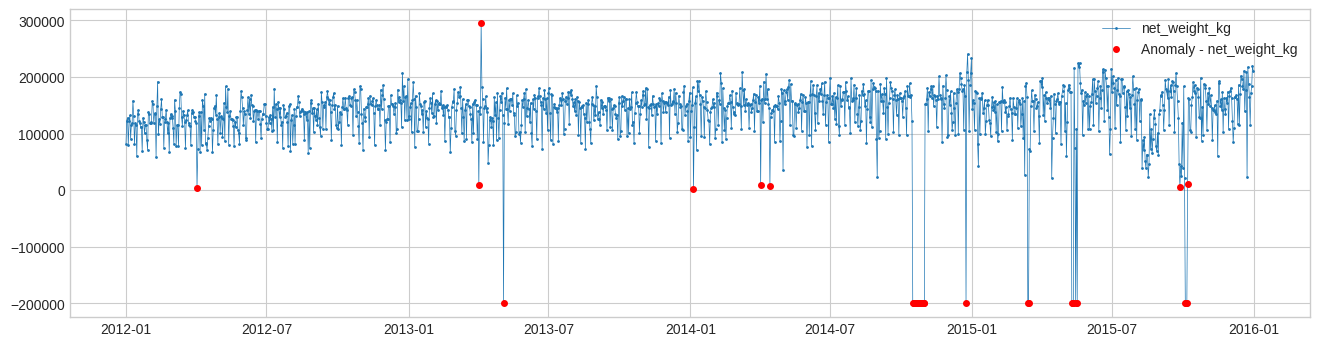

In [42]:
from adtk.detector import SeasonalAD
from adtk.visualization import plot

# Create the seasonal anomaly detector
seasonal_ad = SeasonalAD()

# Detect anomalies in the time-series data
anomalies = seasonal_ad.fit_detect(df)

# Plot the original data and highlight anomalies
plot(
    df,
    anomaly=anomalies,
    anomaly_color="red",
    anomaly_tag="marker"
)

Remove outliers

In [43]:
anomalies_mask = np.array(anomalies.reset_index()['net_weight_kg'].tolist())

In [44]:
print(f'outliers: {anomalies_mask.sum() - missing_value_count}')

#original - 29

outliers: 8


In [45]:
df['net_weight_kg'] = df['net_weight_kg'].iloc[~anomalies_mask]

In [46]:
df = df.reset_index()

Set (Saturdays, Sundays) detected as outliers to 0

In [47]:
# df['net_weight_kg'].loc[(df['ticket_date'].dt.dayofweek == 5) | (df['ticket_date'].dt.dayofweek == 6)] = 0

### Waste Data Visualization

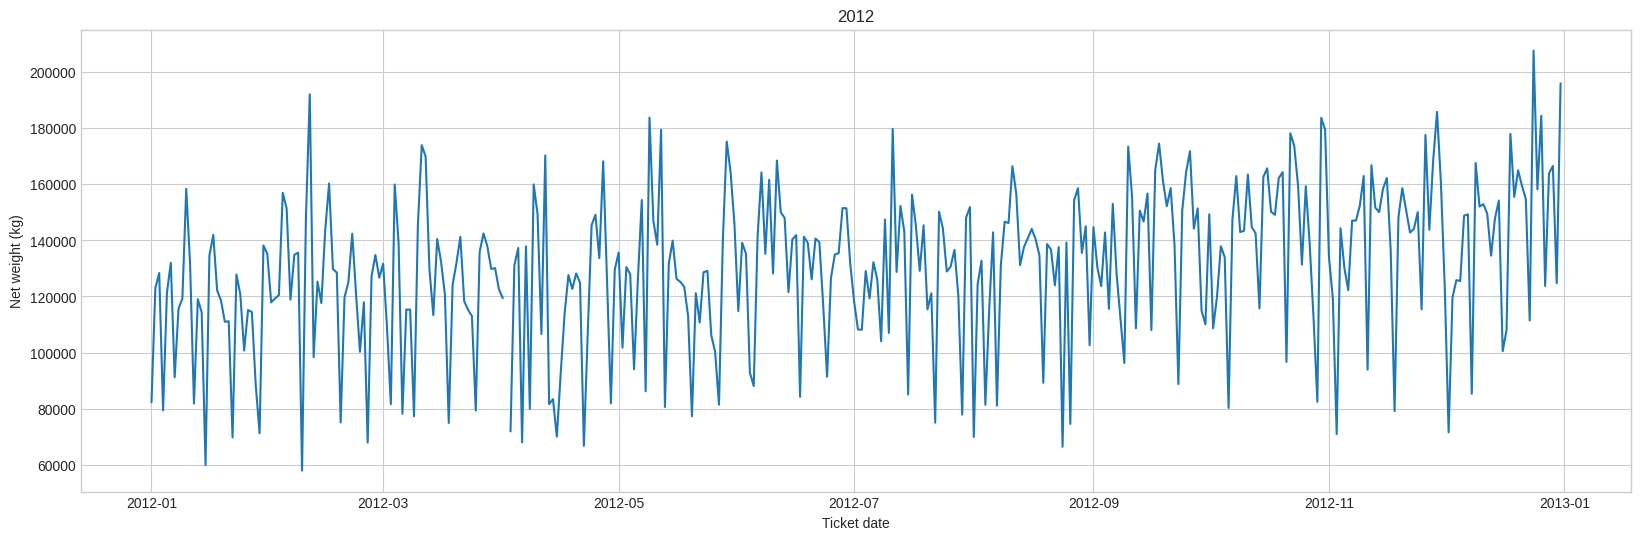

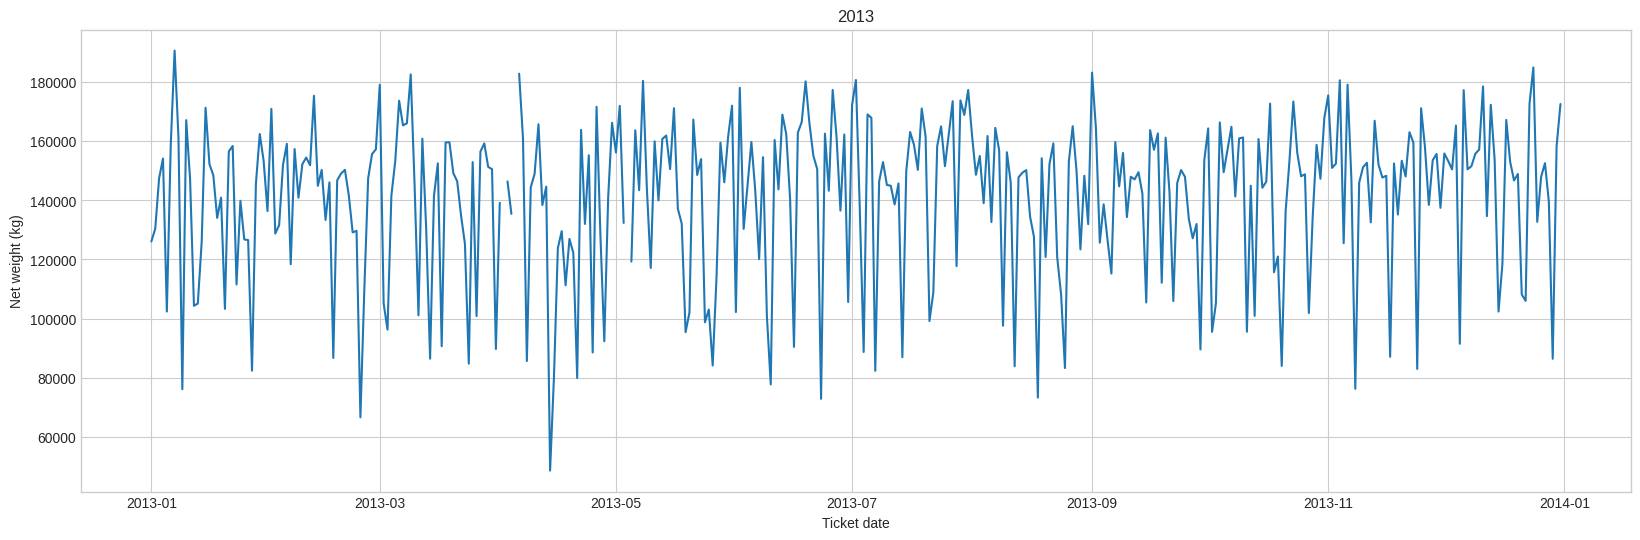

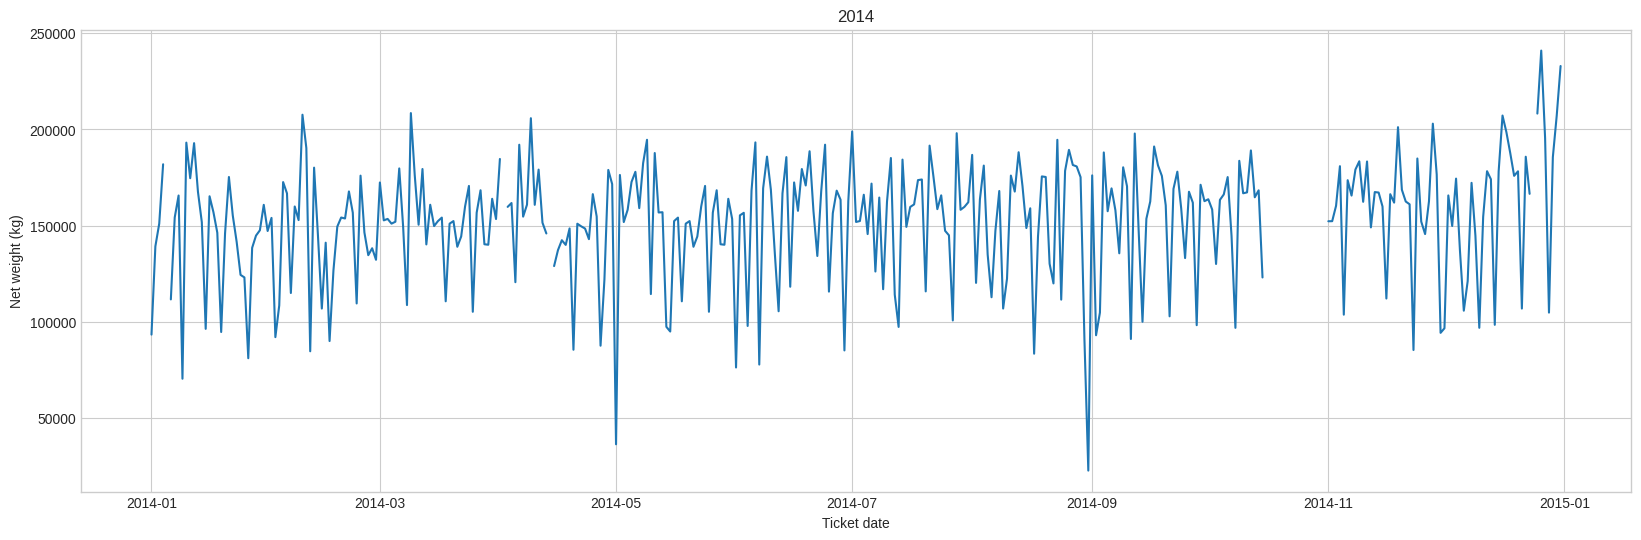

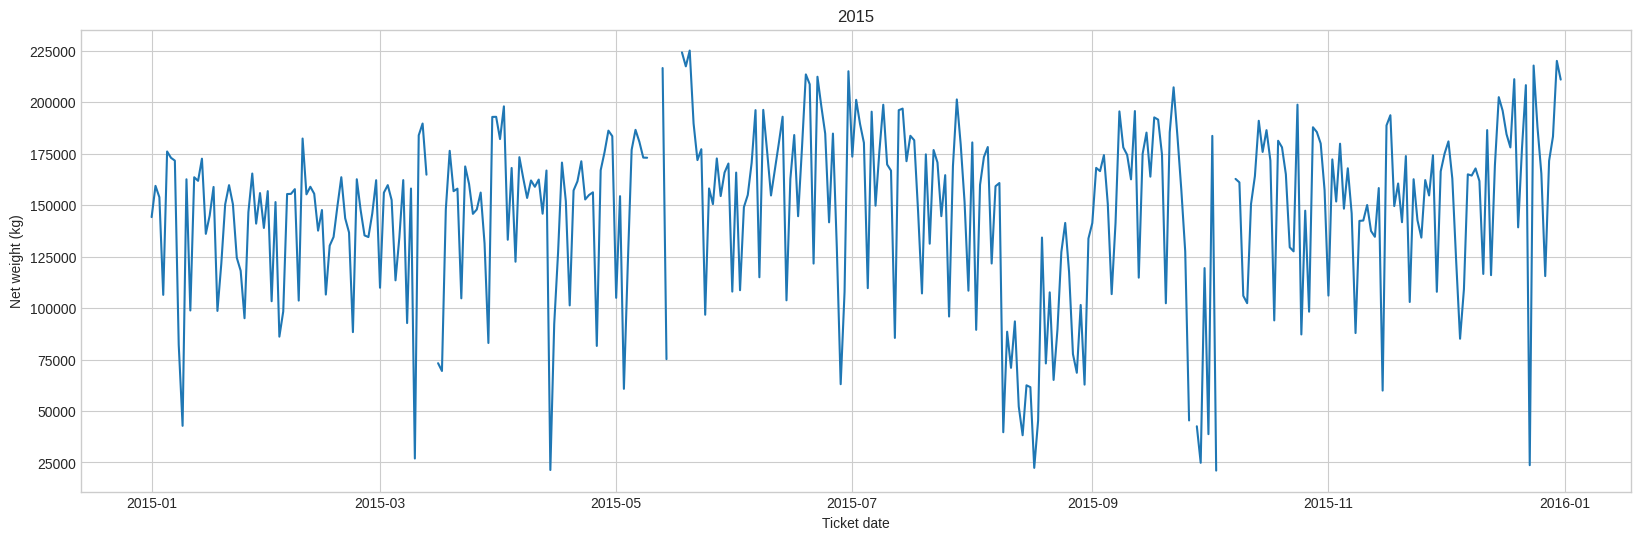

In [48]:
for year in range(2012, 2016):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

### best model selection

Hyperparameter tuning for XGBoost

In [49]:
# lag_count_list = [
#     1, 2, 3, 4, 5, 6, 7,
#     14, 21, 28, 35, 42, 49, 56,
#     30, 60, 90, 120, 150, 180, 360
# ]

# estimator_count_list = [10, 100, 1000]
# max_depth_list = [3, 4, 5, 6, 7, 8, 9]
# subsample_list = [0.5, 0.6, 0.7, 0.8, 0.9]
# eta_list = [0.001, 0.01, 0.1, 0.2, 0.3]

# n_iter = (
#     len(lag_count_list)
#     * len(estimator_count_list)
#     * len(max_depth_list)
#     * len(subsample_list)
#     * len(eta_list)
# )

# print("Total configurations:", n_iter)

In [50]:
lag_count_list = [120, 90]

estimator_count_list = [1000]

max_depth_list = [8, 7]

subsample_list = [0.9, 0.6]

eta_list = [0.1, 0.01]

# Calculate total configurations
n_iter = (
    len(lag_count_list)
    * len(estimator_count_list)
    * len(max_depth_list)
    * len(subsample_list)
    * len(eta_list)
)

print("Total configurations:", n_iter)

Total configurations: 16


In [51]:
def evaluate(lag_count, estimator_count, max_depth, subsample, eta):

    df_temp = df.copy()

    # Create lag features from previous days
    for i in range(1, lag_count + 1):
        df_temp[f'net_weight_kg_lag_{i}'] = (
            df_temp['net_weight_kg'].shift(i)
        )

    # Remove rows missing the target or required lag values
    lag_columns = [
        f'net_weight_kg_lag_{i}'
        for i in range(1, lag_count + 1)
    ]

    df_temp = df_temp.dropna(
        subset=['net_weight_kg'] + lag_columns
    )

    # Separate features and target
    X = df_temp.drop(columns=['ticket_date', 'net_weight_kg'])
    y = df_temp['net_weight_kg']

    # Split chronologically: first 80% for training, last 20% for testing
    split_index = int(len(df_temp) * 0.8)

    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    model = xgboost.XGBRegressor(
        n_estimators=estimator_count,
        random_state=0,
        max_depth=max_depth,
        subsample=subsample,
        learning_rate=eta,
        objective='reg:squarederror',
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = sqrt(mean_squared_error(y_test, y_pred))

    return rmse

In [52]:
# test_rmse = evaluate(
#     lag_count=7,
#     estimator_count=10,
#     max_depth=3,
#     subsample=0.8,
#     eta=0.1
# )

# print("Test RMSE:", test_rmse)

In [53]:
results = []
errors = []

with tqdm(total=n_iter, desc="Grid Search") as pbar:

    for lag_count in lag_count_list:
        for estimator_count in estimator_count_list:
            for max_depth in max_depth_list:
                for subsample in subsample_list:
                    for eta in eta_list:

                        filename = (
                            f'lag-{lag_count}'
                            f'_est-{estimator_count}'
                            f'_dpt-{max_depth}'
                            f'_subsmp-{subsample}'
                            f'_eta-{eta}.json'
                        )

                        file_path = os.path.join(
                            PREPROCESSING_CACHE_DIR_PATH,
                            filename
                        )

                        try:
                            if os.path.exists(file_path):
                                with open(file_path, 'r') as f:
                                    summary = json.load(f)
                            else:
                                rmse = evaluate(
                                    lag_count,
                                    estimator_count,
                                    max_depth,
                                    subsample,
                                    eta
                                )

                                summary = {
                                    'rmse': float(rmse),
                                    'lag_count': lag_count,
                                    'estimator_count': estimator_count,
                                    'max_depth': max_depth,
                                    'subsample': subsample,
                                    'eta': eta
                                }

                                with open(file_path, 'w') as f:
                                    json.dump(summary, f, indent=4)

                            results.append(summary)

                        except Exception as e:
                            errors.append({
                                'filename': filename,
                                'error': str(e)
                            })

                        finally:
                            pbar.update(1)

print("Completed.")
print("Successful results:", len(results))
print("Failed configurations:", len(errors))

Grid Search:   0%|          | 0/16 [00:00<?, ?it/s]

/tmp/ipykernel_10755/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp[f'net_weight_kg_lag_{i}'] = (
/tmp/ipykernel_10755/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp[f'net_weight_kg_lag_{i}'] = (
/tmp/ipykernel_10755/583705414.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `new

Completed.
Successful results: 16
Failed configurations: 0


In [54]:
if results:
    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        'rmse'
    ).reset_index(drop=True)

    display(results_df.head(10))

    print("Best configuration:")
    display(results_df.iloc[[0]])

    results_df.to_csv(
        '/content/preprocessing_cache/all_grid_search_results_austin.csv',
        index=False
    )

,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,31749.758202,120,1000,8,0.9,0.10
1,32009.411058,120,1000,8,0.9,0.01
2,32290.108148,120,1000,7,0.9,0.01
3,32702.051234,120,1000,7,0.9,0.10
4,33517.784637,120,1000,7,0.6,0.10
5,33568.129666,120,1000,8,0.6,0.01
6,33695.227856,120,1000,7,0.6,0.01
7,34105.137339,120,1000,8,0.6,0.10
8,38956.016242,90,1000,7,0.6,0.01
9,38962.175834,90,1000,8,0.6,0.01


Best configuration:


,rmse,lag_count,estimator_count,max_depth,subsample,eta
0,31749.758202,120,1000,8,0.9,0.1


Choosing best model

In [55]:
best_model_list = []

# Use the lag counts from the previous cell
for lag_count in lag_count_list:

    temp_results = []

    for dir_name in os.listdir(PREPROCESSING_CACHE_DIR_PATH):

        # Find result files matching this lag count
        if dir_name.startswith(f'lag-{lag_count}_') and dir_name.endswith('.json'):

            file_path = os.path.join(
                PREPROCESSING_CACHE_DIR_PATH,
                dir_name
            )

            try:
                with open(file_path, 'r') as f:
                    summary = json.load(f)

                # Check whether the result matches the values tested
                if (
                    summary['lag_count'] in lag_count_list
                    and summary['estimator_count'] in estimator_count_list
                    and summary['max_depth'] in max_depth_list
                    and summary['subsample'] in subsample_list
                    and summary['eta'] in eta_list
                ):
                    temp_results.append(
                        (summary['rmse'], summary)
                    )

            except (json.JSONDecodeError, KeyError, OSError) as e:
                print(f"Could not read {dir_name}: {e}")

    # Select the configuration with the lowest RMSE
    temp_results.sort(key=lambda x: x[0])

    if temp_results:
        best_model_list.append(temp_results[0])
    else:
        print(f"No matching result found for lag count {lag_count}.")

# Display the best result for each lag count
for rmse, summary in best_model_list:

    model_name = (
        'Single model'
        if summary['lag_count'] == 120
        else 'Multi-model'
    )

    print(f"\nModel: {model_name}")
    print(f"RMSE: {rmse:.4f}")
    print(f"Lag count: {summary['lag_count']}")
    print(f"Estimators: {summary['estimator_count']}")
    print(f"Max depth: {summary['max_depth']}")
    print(f"Subsample: {summary['subsample']}")
    print(f"Eta: {summary['eta']}")


Model: Single model
RMSE: 31749.7582
Lag count: 120
Estimators: 1000
Max depth: 8
Subsample: 0.9
Eta: 0.1

Model: Multi-model
RMSE: 38956.0162
Lag count: 90
Estimators: 1000
Max depth: 7
Subsample: 0.6
Eta: 0.01


In [56]:
optimum_lag_model_params = sorted(best_model_list, key=lambda x: x[0])[0][1]
display(optimum_lag_model_params)

{'rmse': 31749.75820162406,
 'lag_count': 120,
 'estimator_count': 1000,
 'max_depth': 8,
 'subsample': 0.9,
 'eta': 0.1}

In [57]:
for rmse, params in sorted(best_model_list, key=lambda x: x[0]):
    print("\nRMSE:", rmse)
    display(params)


RMSE: 31749.75820162406


{'rmse': 31749.75820162406,
 'lag_count': 120,
 'estimator_count': 1000,
 'max_depth': 8,
 'subsample': 0.9,
 'eta': 0.1}


RMSE: 38956.01624160401


{'rmse': 38956.01624160401,
 'lag_count': 90,
 'estimator_count': 1000,
 'max_depth': 7,
 'subsample': 0.6,
 'eta': 0.01}

In [58]:
first_null_index = df[df.isnull().any(axis=1)].index[0]
modified_best_model_list = [model for model in best_model_list if model[1]['lag_count'] < first_null_index]
minimum_lag_model_params = sorted(modified_best_model_list, key=lambda x: x[0])[0][1]
display(minimum_lag_model_params)

{'rmse': 38956.01624160401,
 'lag_count': 90,
 'estimator_count': 1000,
 'max_depth': 7,
 'subsample': 0.6,
 'eta': 0.01}

In [59]:
# Find the first row containing a missing value
null_rows = df.index[df.isnull().any(axis=1)]

if len(null_rows) > 0:
    first_null_index = null_rows[0]
else:
    first_null_index = len(df)

print("First missing row index:", first_null_index)

# Keep configurations with lag counts smaller than this index
modified_best_model_list = [
    model for model in best_model_list
    if model[1]['lag_count'] < first_null_index
]

if modified_best_model_list:
    # Select the configuration with the lowest RMSE
    minimum_lag_model_params = min(
        modified_best_model_list,
        key=lambda x: x[0]
    )[1]

    display(minimum_lag_model_params)
else:
    print("No configurations satisfy the lag-count condition.")

First missing row index: 92


{'rmse': 38956.01624160401,
 'lag_count': 90,
 'estimator_count': 1000,
 'max_depth': 7,
 'subsample': 0.6,
 'eta': 0.01}

Impute missing data

In [60]:
def evaluate_forecast(actual, predicted, plot_title=None):
    rmse = None
    mae = None
    mape = None

    try:
        rmse = sqrt(mean_squared_error(actual, predicted))
        print('RMSE: {}'.format(rmse))
    except:
        print(actual)
        print(predicted)
        traceback.print_exc()

    try:
        mae = mean_absolute_error(actual, predicted)
        print('MAE: {}'.format(mae))
    except:
        traceback.print_exc()

    try:
        mape = mean_absolute_percentage_error(actual, predicted)
        print('MAPE: {}'.format(mape))
    except:
        traceback.print_exc()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)
    plt.plot(actual)
    plt.plot(predicted)
    if not plot_title: plt.title(plot_title)
    plt.show()

    return rmse, mae, mape

In [61]:
# import matplotlib.pyplot as plt

# actual = [65000, 68000, 70000, 72000, 69000]
# predicted = [66000, 67000, 71000, 70000, 69500]

# rmse, mae, mape = evaluate_forecast(
#     actual,
#     predicted,
#     plot_title='Ballarat Daily Waste Forecast'
# )

Model Selection

Optimum lag model

/tmp/ipykernel_10755/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_10755/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)
/tmp/ipykernel_10755/1781415569.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all colu

RMSE: 22245.498600840576
MAE: 16671.91796875
MAPE: 0.13888300955295563


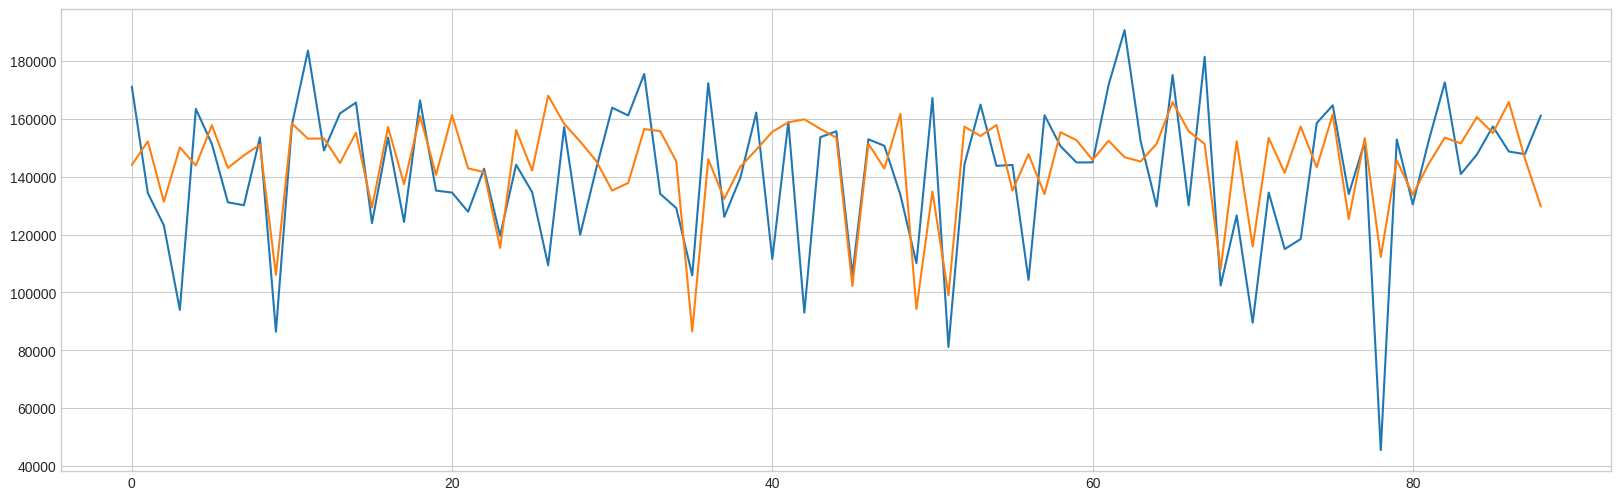

(22245.498600840576, 16671.91796875, 0.13888300955295563)

In [62]:
df_temp = df.copy()

# Create lag features
for i in range(1, optimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_optimum = xgboost.XGBRegressor(
    n_estimators=optimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=optimum_lag_model_params['max_depth'],
    subsample=optimum_lag_model_params['subsample'],
    eta=optimum_lag_model_params['eta']
)
model_optimum.fit(X_train, y_train)

y_pred = model_optimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [63]:
# Check actual values in the evaluation set
y_test_array = np.asarray(y_test)

print("Number of test observations:", len(y_test_array))
print("Zero actual values:", np.sum(y_test_array == 0))
print("Negative actual values:", np.sum(y_test_array < 0))
print("Near-zero actual values:", np.sum(np.abs(y_test_array) < 1e-8))
print("Minimum actual value:", np.min(y_test_array))

Number of test observations: 89
Zero actual values: 0
Negative actual values: 0
Near-zero actual values: 0
Minimum actual value: 45410.0


Minimum lag model

RMSE: 22760.158874665176
MAE: 18724.71484375
MAPE: 0.15215878188610077


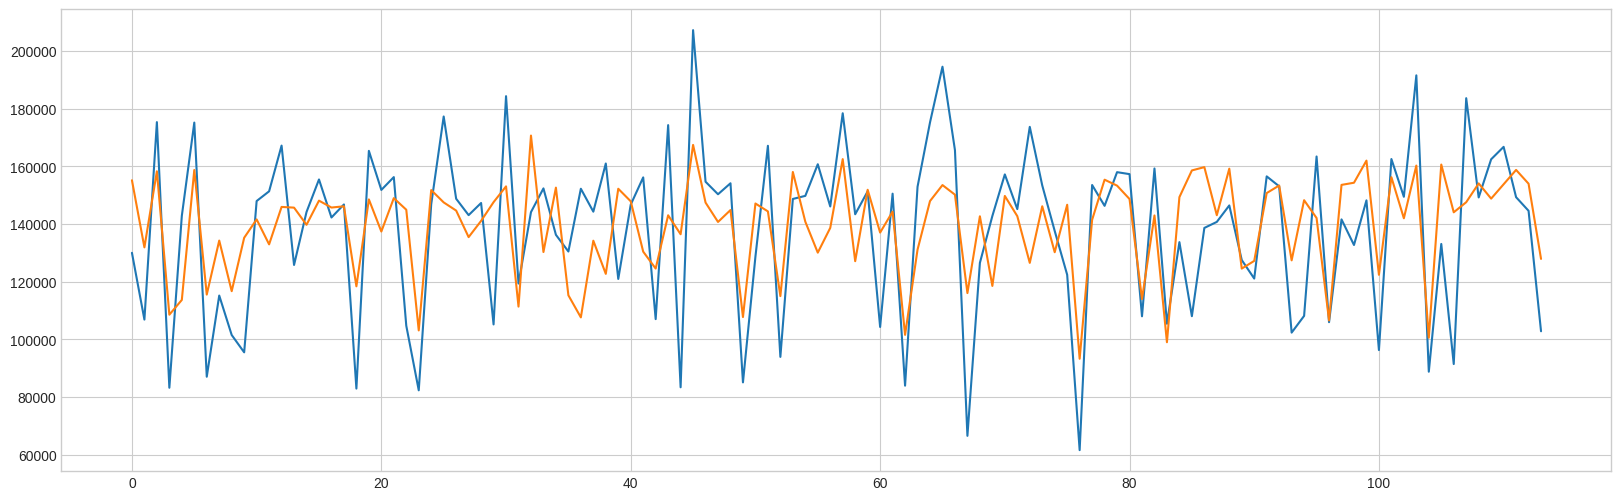

(22760.158874665176, 18724.71484375, 0.15215878188610077)

In [64]:
df_temp = df.copy()

# Create lag features
for i in range(1, minimum_lag_model_params['lag_count'] + 1):
    df_temp['net_weight_kg_lag_{}'.format(i)] = df_temp['net_weight_kg'].shift(i)

df_temp = df_temp.dropna()

del df_temp['ticket_date']

# Split the dataset
X = df_temp.drop(['net_weight_kg'], axis=1)
y = df_temp['net_weight_kg'].tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

model_minimum = xgboost.XGBRegressor(
    n_estimators=minimum_lag_model_params['estimator_count'],
    seed=0,
    max_depth=minimum_lag_model_params['max_depth'],
    subsample=minimum_lag_model_params['subsample'],
    eta=minimum_lag_model_params['eta']
)
model_minimum.fit(X_train, y_train)

y_pred = model_minimum.predict(X_test)

evaluate_forecast(y_test, y_pred)

In [65]:
# Impute data
df['predicted_net_weight_kg'] = np.nan
for index, row in df.iterrows():
    ticket_date = row['ticket_date']
    net_weight_kg = row['net_weight_kg']

    if not pd.notnull(row['net_weight_kg']):
        if index > optimum_lag_model_params['lag_count']:
            previous_values = df[index - optimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, optimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_optimum.predict(previous_df)
        else:
            previous_values = df[index - minimum_lag_model_params['lag_count']:index]['net_weight_kg'].tolist()[::-1]
            column_list = []
            for i in range(1, minimum_lag_model_params['lag_count'] + 1):
                column_list.append('net_weight_kg_lag_{}'.format(i))

            previous_df = pd.DataFrame([previous_values], columns=column_list)
            current_value_pred = model_minimum.predict(previous_df)

        df.at[index,'net_weight_kg'] = current_value_pred
        df.at[index,'predicted_net_weight_kg'] = current_value_pred

In [66]:
print(f' imputed values: {df["predicted_net_weight_kg"].count()}')
print(f'Percentage of imputed values: {df["predicted_net_weight_kg"].count() / df["predicted_net_weight_kg"].isna().sum() * 100.0}')
print(f'Mean daily weight: {df["predicted_net_weight_kg"].mean()}')
print(f'SD daily weight: {df["predicted_net_weight_kg"].std()}')

 imputed values: 36
Percentage of imputed values: 2.526315789473684
Mean daily weight: 148088.24587673612
SD daily weight: 22969.905327499462


## Actual versus predicted daily waste weight for each year from 2012 to 2016

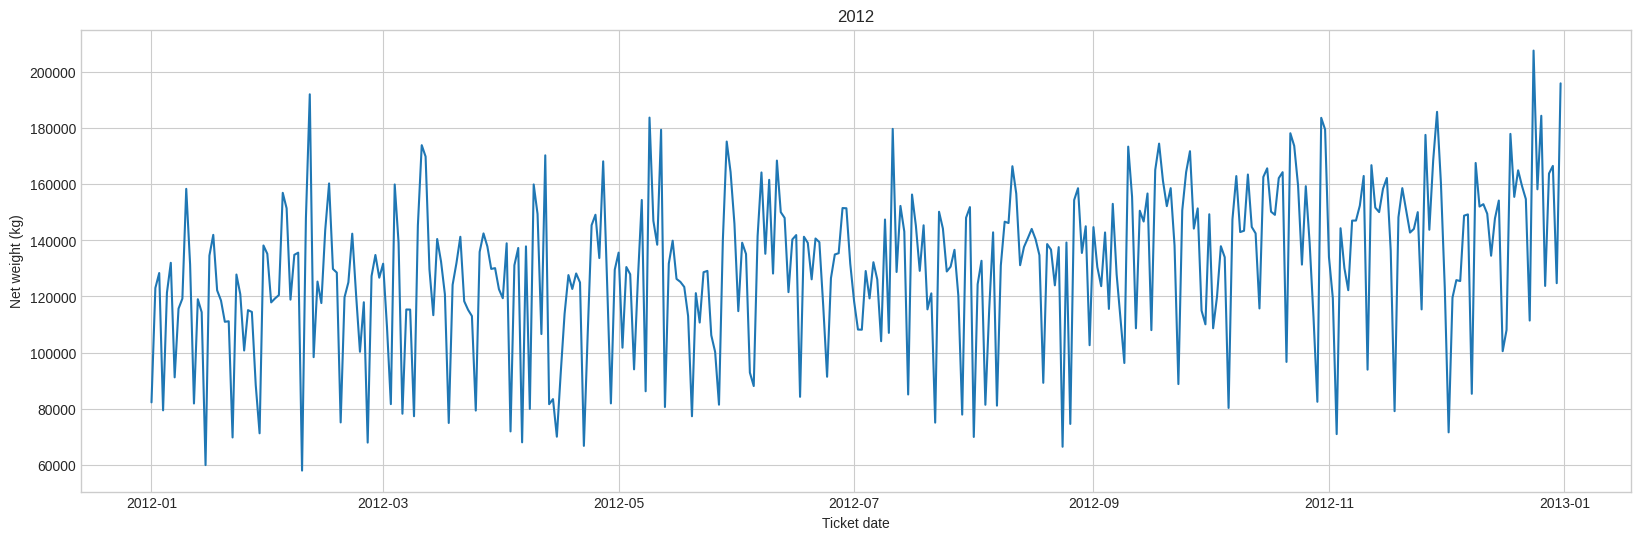

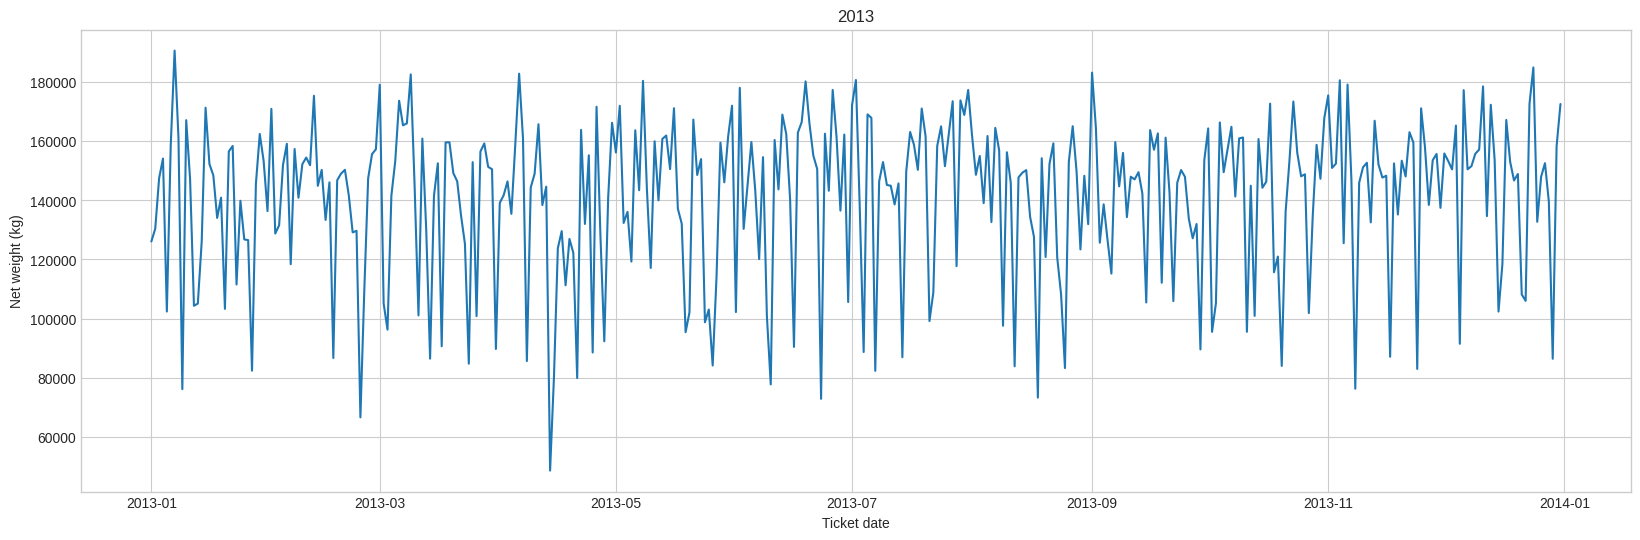

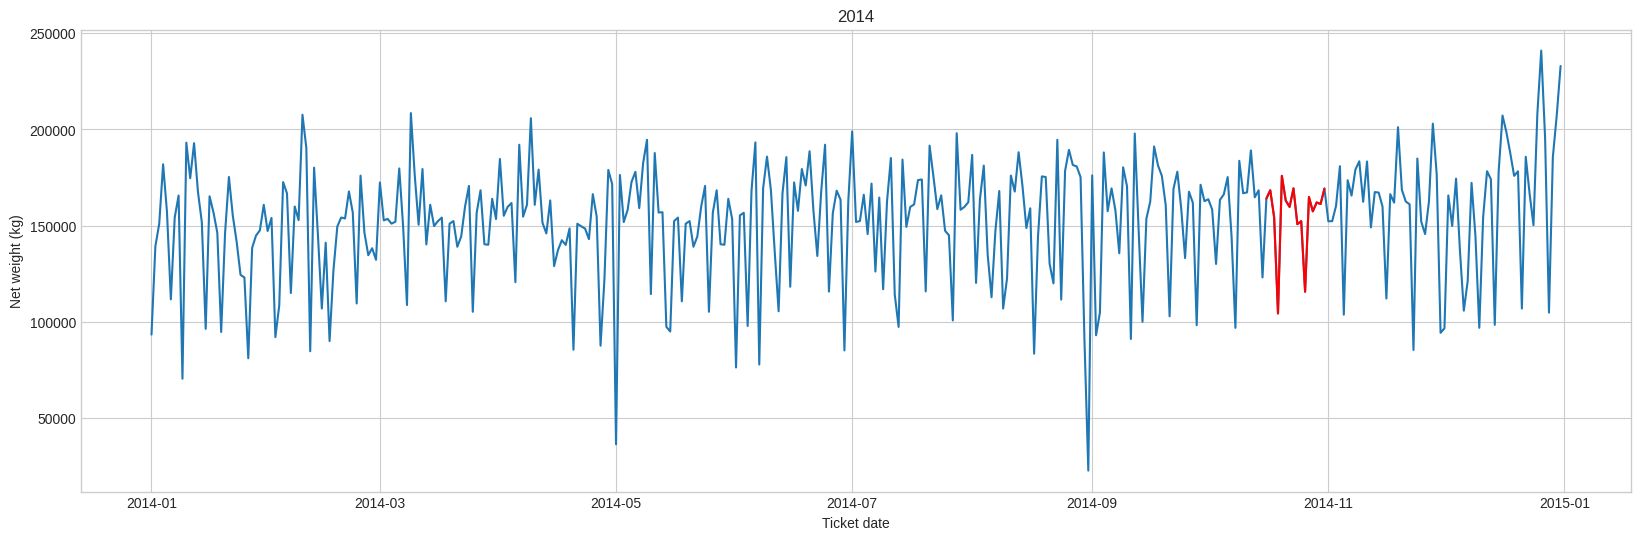

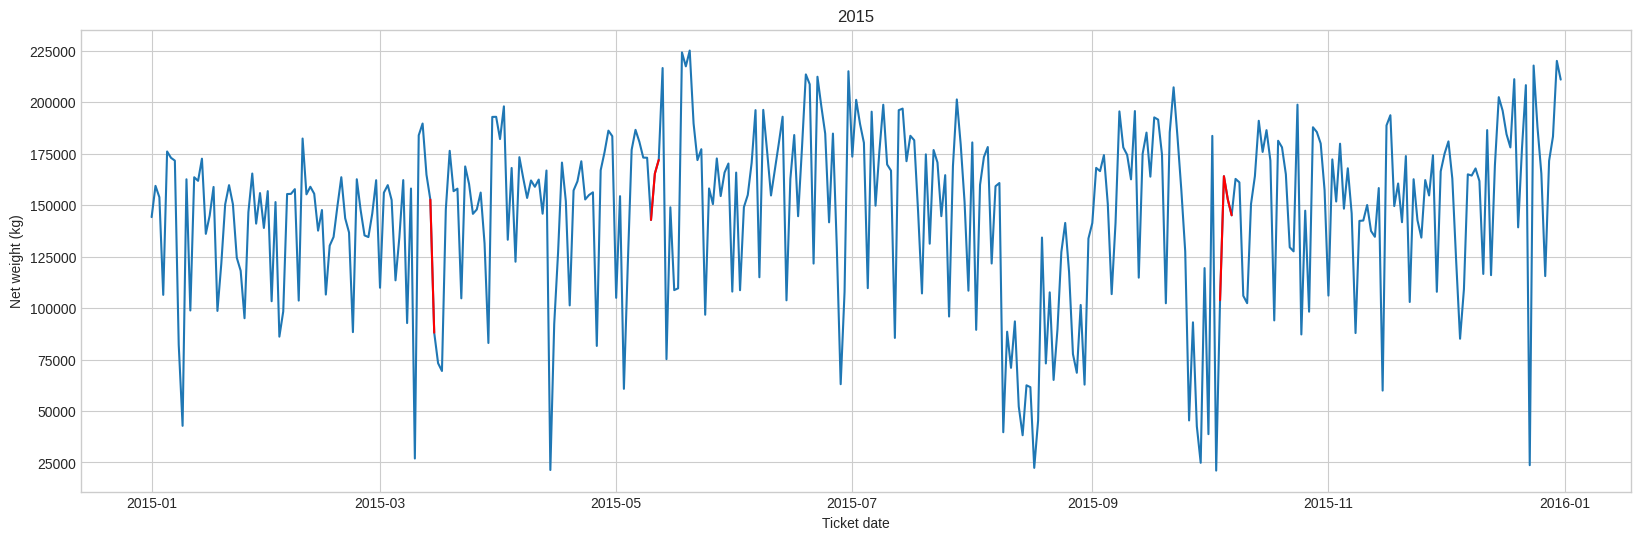

In [67]:
for year in range(2012, 2016):
    x = df[df['ticket_date'].dt.year == year]['ticket_date'].tolist()
    y = df[df['ticket_date'].dt.year == year]['net_weight_kg'].tolist()
    y_pred = df[df['ticket_date'].dt.year == year]['predicted_net_weight_kg'].tolist()

    plt.rcParams['figure.dpi'] = 100
    plt.rcParams["figure.figsize"] = (20, 6)

    plt.plot(x, y)
    plt.plot(x, y_pred, color='red')
    plt.title('{}'.format(year))
    plt.xlabel('Ticket date')
    plt.ylabel('Net weight (kg)')
    plt.show()

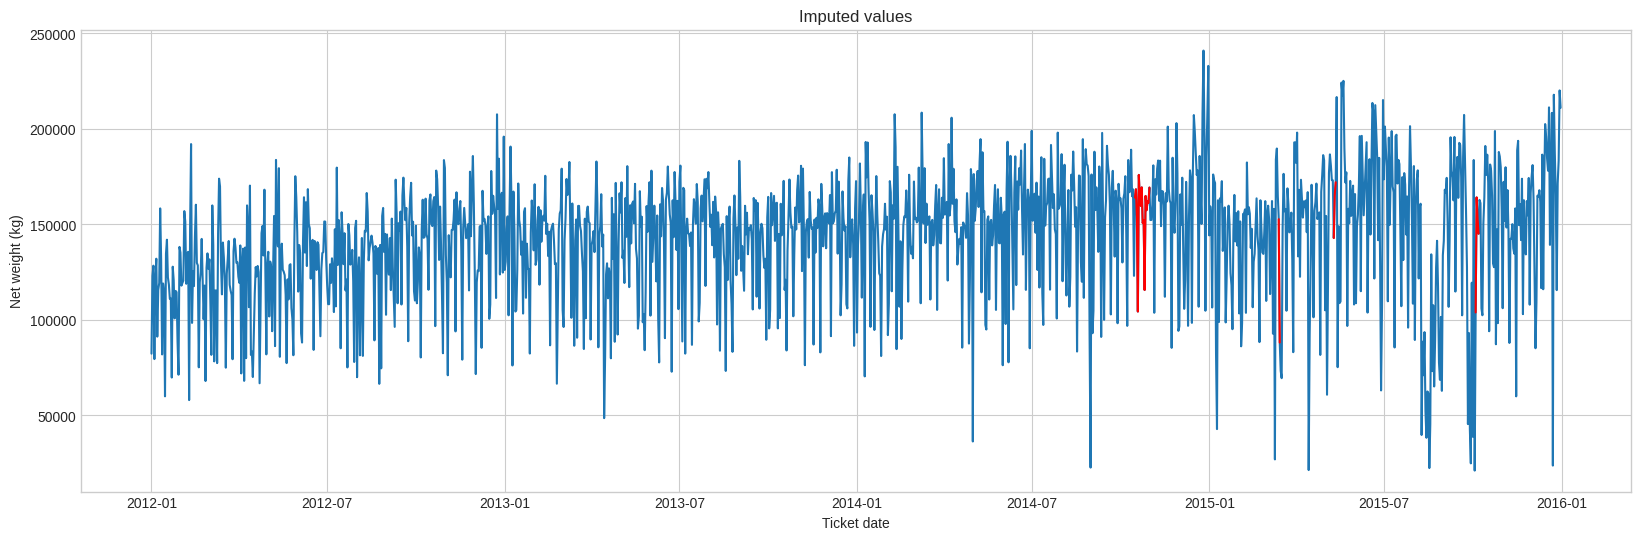

In [68]:
x = df['ticket_date'].tolist()
y = df['net_weight_kg'].tolist()
y_pred = df['predicted_net_weight_kg'].tolist()

plt.plot(x, y)
plt.plot(x, y_pred, color='red')
plt.title('Imputed values')
plt.xlabel('Ticket date')
plt.ylabel('Net weight (kg)')
plt.show()

In [69]:
df_backup = df.copy()
del df['predicted_net_weight_kg']

In [70]:
DAILY_WASTE_OUTPUT_DATA_FILE_PATH = '/content/daily_waste_output_Dehiwala.csv'

df.to_csv(DAILY_WASTE_OUTPUT_DATA_FILE_PATH, index=False)

print("File saved successfully:", DAILY_WASTE_OUTPUT_DATA_FILE_PATH)

File saved successfully: /content/daily_waste_output_Dehiwala.csv
